# Section 3 — Out-of-Sample Distribution and Portfolio Risk Validation

**Test: 2024–2025.** Fit and validate a fixed-weight portfolio distribution. 

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import logsumexp
from sklearn.mixture import GaussianMixture

DATA = Path('research_data')
DATA.mkdir(exist_ok=True)

train = pd.read_csv(DATA / 'train_log_returns_2021_2023.csv', index_col=0, parse_dates=True)
test = pd.read_csv(DATA / 'test_log_returns_2024_2025.csv', index_col=0, parse_dates=True)
params = pd.read_csv(DATA / 'fitted_models_2021_2023.csv').set_index('ticker')

## 1. Evaluate stock-level test log score
A higher mean log density is better.

In [4]:
scores = []

for ticker, row in params.iterrows():
    x = test[ticker].dropna().to_numpy()
    n = stats.norm.logpdf(x, row.normal_mu, row.normal_sigma)
    t = stats.t.logpdf(x, row.t_df, loc=row.t_loc, scale=row.t_scale)
    g = logsumexp(np.stack([np.log(row.gmm_weight_1) + stats.norm.logpdf(x, row.gmm_mean_1, row.gmm_std_1), np.log(row.gmm_weight_2) + stats.norm.logpdf(x, row.gmm_mean_2, row.gmm_std_2)]), axis=0)
    for model, v in [('Normal', n), ('Student-t', t), ('GMM', g)]:
        scores.append(dict(ticker=ticker, model=model, mean_test_log_score=float(np.mean(v)), n_test=len(x)))

# Save resultes
stock_scores = pd.DataFrame(scores)
stock_scores.to_csv(DATA / 'stock_test_log_scores.csv', index=False)

## 2. Construct a fixed-weight portfolio
The four selected stocks are META, NVDA, XOM, CVX. Daily **simple** portfolio returns use daily rebalancing to equal weights

In [6]:
ASSETS = ['META', 'NVDA', 'XOM', 'CVX']

w = np.repeat(1 / len(ASSETS), len(ASSETS))

def portfolio_returns(logret):
    return (np.expm1(logret[ASSETS]) @ w).rename('portfolio_return')

p_train = portfolio_returns(train)
p_test = portfolio_returns(test)
print('Training portfolio days:', len(p_train), 'Test days:', len(p_test))


Training portfolio days: 752 Test days: 502


## 3. Fit portfolio Normal, Student-t and GMM on training returns

In [7]:
x = 100 * p_train.to_numpy()
y = 100 * p_test.to_numpy()

normal = stats.norm.fit(x)
student = stats.t.fit(x)
gmm = GaussianMixture(n_components=2, n_init=15, random_state=42, reg_covar=1e-06).fit(x.reshape(-1, 1))

models = {'Normal': normal, 'Student-t': student, 'GMM': gmm}
print('Normal (percent):', normal, 'Student-t (percent):', student)

Normal (percent): (np.float64(0.14321699807938743), np.float64(1.7192362096098843)) Student-t (percent): (np.float64(5.745491184966852), np.float64(0.15070122435788305), np.float64(1.3946231298554301))


## 4. Quantile and Expected Shortfall calculation

In [8]:
from scipy.optimize import brentq

def model_cdf(x, model):
    if model == 'Normal':
        return stats.norm.cdf(x, *normal)
    if model == 'Student-t':
        return stats.t.cdf(x, *student)
    z = (x - gmm.means_.ravel()) / np.sqrt(gmm.covariances_.ravel())
    return float(np.sum(gmm.weights_ * stats.norm.cdf(z)))

In [9]:
def risk_numbers(model, alpha):
    if model == 'Normal':
        q = stats.norm.ppf(alpha, *normal)
        mu, sd = normal
        left = mu - sd * stats.norm.pdf(stats.norm.ppf(alpha)) / alpha
    elif model == 'Student-t':
        nu, loc, scale = student
        if nu <= 1:
            raise ValueError('Student-t ES undefined for df<=1')
        z = stats.t.ppf(alpha, nu)
        q = loc + scale * z
        left = loc - scale * ((nu + z * z) / (nu - 1)) * stats.t.pdf(z, nu) / alpha
    else:
        q = brentq(lambda v: model_cdf(v, 'GMM') - alpha, -100, 100)
        means = gmm.means_.ravel()
        sds = np.sqrt(gmm.covariances_.ravel())
        z = (q - means) / sds
        left = np.sum(gmm.weights_ * (means * stats.norm.cdf(z) - sds * stats.norm.pdf(z))) / alpha
    return {'quantile_pct': q, 'VaR_frac': max(0, -q / 100), 'ES_frac': max(0, -left / 100)}

In [ ]:
risk_rows = []

for model in models:
    for alpha in [0.05, 0.01]:
        d = risk_numbers(model, alpha)
        breaches = int(np.sum(y < d['quantile_pct']))
        observed_es = -float(np.mean(y[y < d['quantile_pct']])) / 100 if breaches else np.nan
        risk_rows.append(dict(model=model, 
                            confidence=1 - alpha, 
                            breaches=breaches, 
                            expected_breaches=len(y) * alpha, 
                            breach_rate=breaches / len(y), 
                            realized_breach_mean_loss=observed_es, **d
                            ))

# Save results
risk_table = pd.DataFrame(risk_rows)
display(risk_table.round(5))
risk_table.to_csv(DATA / 'portfolio_var_es_backtest.csv', index=False)

,model,confidence,breaches,expected_breaches,breach_rate,realized_breach_mean_loss,quantile_pct,VaR_frac,ES_frac
0,Normal,0.95,12,25.10,0.02390,0.04251,-2.68467,0.02685,0.03403
1,Normal,0.99,6,5.02,0.01195,0.05448,-3.85632,0.03856,0.04439
2,Student-t,0.95,14,25.10,0.02789,0.04015,-2.58095,0.02581,0.03683
3,Student-t,0.99,4,5.02,0.00797,0.06200,-4.29793,0.04298,0.05595
4,GMM,0.95,12,25.10,0.02390,0.04251,-2.73586,0.02736,0.03489
5,GMM,0.99,5,5.02,0.00996,0.05753,-3.96453,0.03965,0.04572


## 5. Plot VaR and ES

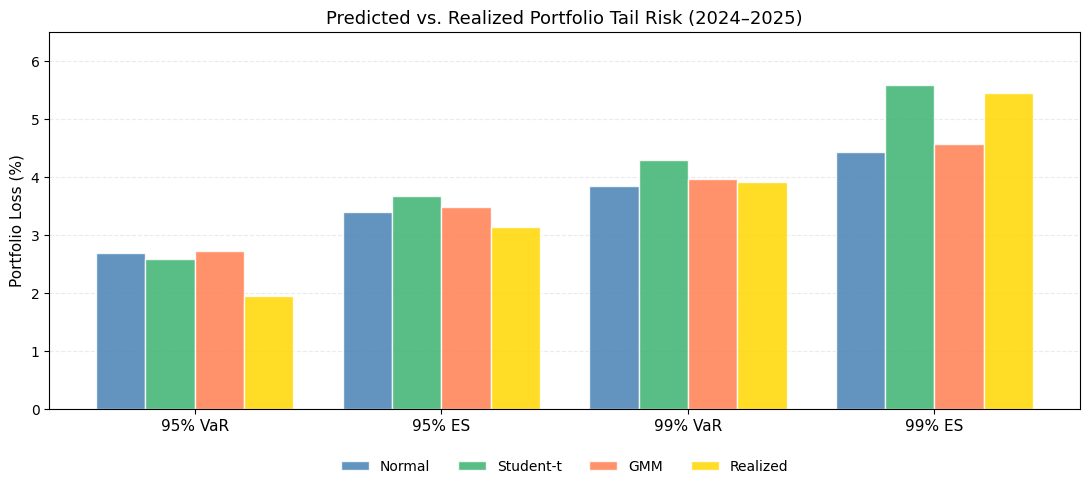

In [26]:
# Figure: Predicted vs. Realized Portfolio VaR and ES

# VaR and ES values
confidence_levels = [0.95, 0.99]
model_names = list(models)
metrics = ['95% VaR', '95% ES', '99% VaR', '99% ES']
model_values = {model: [] for model in model_names}
realized_values = []


for confidence in confidence_levels:
    tail_probability = 1 - confidence

    # Model predictions
    for model in model_names:
        result = risk_numbers(model, tail_probability)
        model_values[model].append(result['VaR_frac'] * 100)
        model_values[model].append(result['ES_frac'] * 100)

    # Realized risk from test-period losses
    losses = -p_test.to_numpy().ravel()
    realized_var = np.quantile(losses, confidence)
    realized_es = losses[losses >= realized_var].mean()
    realized_values.extend([realized_var * 100, realized_es * 100])


# Create grouped bar chart
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(metrics))
width = 0.20
colors = {
    'Normal': 'steelblue',
    'Student-t': 'mediumseagreen',
    'GMM': 'coral',
    'Realized': 'gold'
}


for i, model in enumerate(model_names):
    ax.bar(
        x + (i - 1.5) * width,
        model_values[model],
        width,
        label=model,
        color=colors[model],
        alpha=0.85,
        edgecolor='white'
    )

ax.bar(
    x + 1.5 * width,
    realized_values,
    width,
    label='Realized',
    color=colors['Realized'],
    alpha=0.85,
    edgecolor='white'
)


# Format
ax.set_xticks(x)
ax.set_xticklabels(metrics, fontsize=11)
ax.set_ylabel('Portfolio Loss (%)', fontsize=11)
ax.set_title('Predicted vs. Realized Portfolio Tail Risk (2024–2025)', fontsize=13)
ax.set_ylim(0, 6.5)
ax.grid(axis='y', linestyle='--', alpha=0.25)
ax.set_axisbelow(True)
ax.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, -0.10),
    ncol=4,
    frameon=False,
    fontsize=10
)


# Save figure
plt.tight_layout()
plt.savefig(
    'portfolio_var_es_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

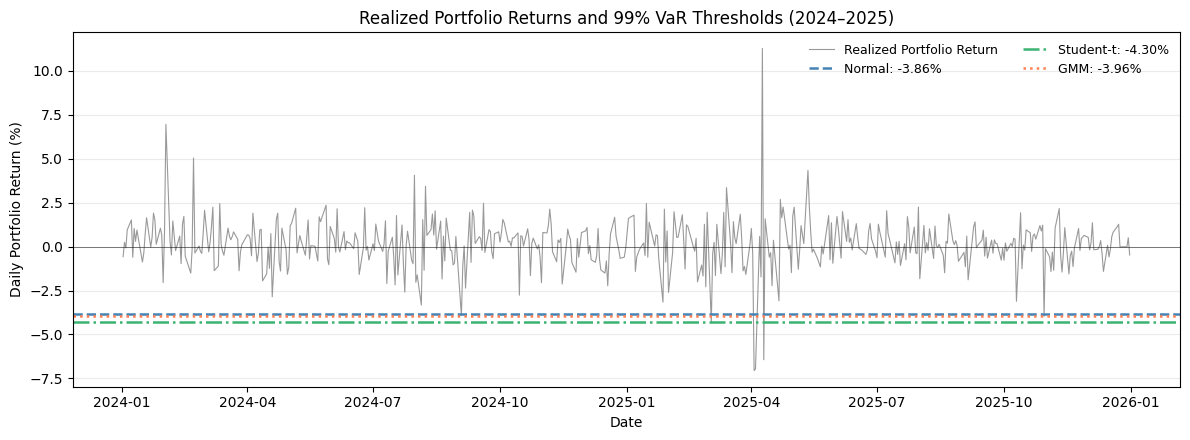

In [29]:
# Figure: Realized Returns and 99% VaR Thresholds

fig, ax = plt.subplots(figsize=(12, 4.5))

# Plot realized daily portfolio returns
ax.plot(
    p_test.index,
    p_test.values * 100,
    color='gray',
    linewidth=0.8,
    alpha=0.8,
    label='Realized Portfolio Return'
)

# Plot 99% VaR thresholds for the three models
model_colors = {
    'Normal': 'steelblue',
    'Student-t': 'mediumseagreen',
    'GMM': 'coral'
}

model_linestyles = {
    'Normal': '--',
    'Student-t': '-.',
    'GMM': ':'
}

for model in models:
    q = risk_numbers(model, 0.01)['quantile_pct']
    ax.axhline(
        q,
        color=model_colors[model],
        linestyle=model_linestyles[model],
        linewidth=1.8,
        label=f'{model}: {q:.2f}%'
    )


# Axis labels and formatting
ax.axhline(
    0,
    color='black',
    linewidth=0.7,
    alpha=0.5
)

ax.set_xlabel('Date')
ax.set_ylabel('Daily Portfolio Return (%)')
ax.set_title('Realized Portfolio Returns and 99% VaR Thresholds (2024–2025)')

ax.grid(axis='y', alpha=0.25)
ax.legend(
    fontsize=9,
    loc='upper right',
    frameon=False,
    ncol=2
)

# Save
plt.tight_layout()
plt.savefig(
    'portfolio_var_99_timeseries.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

## 6. Save portfolio model parameters for Section 4

In [23]:
portfolio_fit = pd.DataFrame([{
    'normal_mu_pct': normal[0], 'normal_sd_pct': normal[1], 
    't_df': student[0], 't_loc_pct': student[1], 't_scale_pct': student[2], 
    'gmm_weight_1': gmm.weights_[0], 'gmm_weight_2': gmm.weights_[1], 
    'gmm_mean_1_pct': gmm.means_[0, 0], 'gmm_mean_2_pct': gmm.means_[1, 0], 
    'gmm_sd_1_pct': np.sqrt(gmm.covariances_[0, 0, 0]), 'gmm_sd_2_pct': np.sqrt(gmm.covariances_[1, 0, 0]), 
    'training_sd_pct': np.std(x, ddof=0)}])

portfolio_fit.to_csv(DATA / 'portfolio_fitted_models_2021_2023.csv', index=False)

p_train.to_csv(DATA / 'portfolio_train_simple_returns.csv')
p_test.to_csv(DATA / 'portfolio_test_simple_returns.csv')